# From Raw Data to Decisions — A Complete Classification Study Guide
### Applying the Data-Mining Pyramid to the Titanic Passenger Dataset

This notebook walks up the pyramid from your lecture notes, **one layer at a time**, on a real, messy, labeled dataset:

```
                 ▲  Decision Making            → Layer 6: extract insight & recommend actions
                ▲▲  Data Presentation          → Layer 5: visualization techniques
               ▲▲▲  Data Mining                → Layer 4: three classifiers + comparison
              ▲▲▲▲  Data Exploration           → Layer 3: statistical summary, querying, reporting
             ▲▲▲▲▲  Preprocessing + Feature Sel→ Layer 2: clean, impute, engineer, encode, select
            ▲▲▲▲▲▲  Data Sources               → Layer 1: where the data comes from, what it means
```

**Why a pyramid?** Each layer depends on the one below it. The higher you go, the *less* data you have but the *more* value it carries: thousands of raw cells at the bottom become a handful of sentences a manager can act on at the top. If a lower layer is weak (dirty data, wrong features), everything above it is weak too — *"garbage in, garbage out."*

**How to study each step.** Every step is explained with four questions:
- **What** are we doing?
- **Why** does it matter?
- **How** do we do it in Python?
- **Watch out** — the common mistake.

**The dataset.** The Titanic passenger list (891 passengers, 12 columns). It is the classic teaching dataset because it is:
- **Labeled** — the `Survived` column (0 = died, 1 = survived) is our target → a **binary classification** problem.
- **Genuinely dirty** — missing ages (≈20%), missing cabins (≈77%), missing ports, fares recorded as 0, free-text names and tickets, a heavily skewed fare column.
- **Interpretable** — you can sanity-check every insight against history, which trains your judgement.

The three classifiers we will compare: **Naive Bayes**, **Decision Tree**, and **Random Forest**.

## 0. Setup
We import everything once at the top (professional habit: anyone reading the notebook sees all dependencies immediately) and fix a **random seed** so every result is reproducible.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                       # same seed → same split, same models, same results
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

---
# LAYER 1 — Data Sources
*Paper, files, web documents, scientific experiments, database systems.*

**What:** Identify where the data comes from, load it, and understand what every column means.
**Why:** You cannot clean or model data you do not understand. Knowing the *source* also tells you what errors to expect: this list was assembled by historians from tickets, crew lists and survivor accounts (**paper records** → transcribed into a **file**, now published as a **web document**). Hand-transcribed historical records ⇒ expect missing and estimated values.

## 1.1 Load the data
Professional habit: write the loader so it works **offline** (local file) and **online** (URL fallback).

In [2]:
LOCAL_FILE = Path("titanic.csv")
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

raw = pd.read_csv(LOCAL_FILE if LOCAL_FILE.exists() else URL)
print(f"Rows: {raw.shape[0]}   Columns: {raw.shape[1]}")
raw.head()

Rows: 891   Columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.050,NaN,S


## 1.2 First structural look — `info()`
`info()` answers three questions at once: how many rows, what type each column is, and how many **non-null** values each has. Any column whose non-null count is below 891 has missing data.

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


**Reading the output:** `Age` (714/891), `Cabin` (204/891) and `Embarked` (889/891) have missing values. `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked` are text and must be converted to numbers before most algorithms can use them.

## 1.3 Data dictionary
A data dictionary is the **contract** between you and the data. Always write one.

| Column | Meaning | Type | Notes |
|---|---|---|---|
| `PassengerId` | Row identifier | ID | No predictive meaning — must be dropped |
| `Survived` | **Target**: 0 = died, 1 = survived | Binary label | What we predict |
| `Pclass` | Ticket class: 1 = upper, 2 = middle, 3 = lower | Ordinal | Proxy for wealth |
| `Name` | Full name incl. title (Mr, Mrs, Master…) | Free text | Title hides age/sex/status info |
| `Sex` | male / female | Nominal | |
| `Age` | Age in years (fractions for infants; `xx.5` = estimated) | Numeric | **~20% missing** |
| `SibSp` | # siblings/spouses aboard | Count | |
| `Parch` | # parents/children aboard | Count | |
| `Ticket` | Ticket number | Messy text | Inconsistent formats |
| `Fare` | Ticket price (pounds) | Numeric | Very skewed; some zeros |
| `Cabin` | Cabin number (first letter = deck) | Messy text | **~77% missing** |
| `Embarked` | Port: C = Cherbourg, Q = Queenstown, S = Southampton | Nominal | 2 missing |

## 1.4 Define the problem precisely
- **Task type:** supervised learning → classification (target is a category, not a number).
- **Target balance:** check it *before* anything else, because it decides which metrics are meaningful.

In [4]:
balance = raw["Survived"].value_counts().rename({0: "Died (0)", 1: "Survived (1)"})
print(pd.DataFrame({"count": balance, "share": (balance / len(raw)).round(3)}))

              count  share
Survived                  
Died (0)        549  0.616
Survived (1)    342  0.384


**Interpretation:** about 62% died and 38% survived. This is **mildly imbalanced**. Consequence: a "model" that always predicts *died* already scores ~62% accuracy. Any real model must clearly beat that **baseline**, and we should look at precision/recall/F1, not accuracy alone.

> **Layer 1 takeaway:** know the source, the meaning of each column, the target, and the class balance before touching anything.

---
# LAYER 2 — Data Preprocessing & Feature Selection
This is the widest layer of the pyramid because it is where most of a data scientist's time goes (often quoted as 60–80%). We follow a disciplined order:

1. **Audit** — measure every quality problem.
2. **Decide** — choose a strategy for each problem *and justify it*.
3. **Engineer** — create better features from messy raw columns.
4. **Split** — separate a test set *before* learning any statistics from the data.
5. **Impute** — fill missing values using statistics learned from the training set only.
6. **Transform & encode** — fix skew, turn text into numbers.
7. **Select** — keep the features that carry signal and are not redundant.

## 2.1 Data-quality audit
### (a) Missing values

In [5]:
def quality_report(df):
    # One table summarising missingness, type and cardinality for every column.
    miss = df.isna().sum()
    return (pd.DataFrame({"missing": miss,
                          "missing_%": (miss / len(df) * 100).round(1),
                          "dtype": df.dtypes.astype(str),
                          "unique_values": df.nunique()})
              .sort_values("missing", ascending=False))

raw_quality = quality_report(raw)
raw_quality

,missing,missing_%,dtype,unique_values
Cabin,687,77.1,str,147
Age,177,19.9,float64,88
Embarked,2,0.2,str,3
PassengerId,0,0.0,int64,891
Name,0,0.0,str,891
Pclass,0,0.0,int64,3
Survived,0,0.0,int64,2
Sex,0,0.0,str,2
Parch,0,0.0,int64,7
SibSp,0,0.0,int64,7


### (b) Is the missingness itself informative?
**Key concept — types of missing data:**
- **MCAR** (Missing Completely At Random): missingness unrelated to anything → safe to impute simply.
- **MAR** (Missing At Random): missingness depends on *other* observed columns.
- **MNAR** (Missing Not At Random): missingness depends on the value itself or the outcome.

Test it: does survival differ between rows **with** and **without** the value?

In [6]:
for col in ["Age", "Cabin"]:
    rates = raw.groupby(raw[col].isna())["Survived"].mean().rename({False: "value present", True: "value MISSING"})
    print(f"Survival rate by missingness of {col}:\n{rates.round(3)}\n")

Survival rate by missingness of Age:
Age
value present    0.406
value MISSING    0.294
Name: Survived, dtype: float64

Survival rate by missingness of Cabin:
Cabin
value present    0.667
value MISSING    0.300
Name: Survived, dtype: float64



**This is our first insight.** Passengers with a recorded cabin survived at ~67%; those without, ~30%. Cabin records survived mostly for wealthier passengers (and for survivors who could be interviewed). So the *missingness* carries information.

**Decision:** we will not throw `Cabin` away blindly — we turn "cabin known?" into a feature (`HasCabin`). For `Age` we also keep a flag `AgeWasMissing` so the model can learn from it if useful.

> **Watch out:** deleting rows with missing values would throw away 20% of the data *and* bias the sample (the deleted rows have a different survival rate).

### (c) Duplicates

In [7]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("Duplicates ignoring PassengerId:", raw.drop(columns="PassengerId").duplicated().sum())

Exact duplicate rows: 0
Duplicates ignoring PassengerId: 0


Always check duplicates **ignoring the ID column** — two identical passengers with different IDs would be a data-entry duplicate. None here.

### (d) Hidden missing values (disguised as real numbers)
A missing value is not always `NaN`. A fare of **0** for a first-class ticket is not a real price — it is unrecorded (crew, guarantee group, complimentary). Treating it as real would teach the model that "free ticket" is a thing.

In [8]:
print("Fare == 0 count:", (raw["Fare"] == 0).sum())
raw.loc[raw["Fare"] == 0, ["Name", "Pclass", "Ticket", "Fare", "Survived"]].head(8)

Fare == 0 count: 15


,Name,Pclass,Ticket,Fare,Survived
179,"Leonard, Mr. Lionel",3,LINE,0.0,0
263,"Harrison, Mr. William",1,112059,0.0,0
271,"Tornquist, Mr. William Henry",3,LINE,0.0,1
277,"Parkes, Mr. Francis ""Frank""",2,239853,0.0,0
302,"Johnson, Mr. William Cahoone Jr",3,LINE,0.0,0
413,"Cunningham, Mr. Alfred Fleming",2,239853,0.0,0
466,"Campbell, Mr. William",2,239853,0.0,0
481,"Frost, Mr. Anthony Wood ""Archie""",2,239854,0.0,0


Several of these are 1st or 2nd class — clearly not real prices. **Decision:** convert `Fare == 0` to `NaN`, then impute it like any other missing value.

### (e) Messy text and inconsistent formats

In [9]:
print("Ticket samples:", raw["Ticket"].sample(8, random_state=1).tolist())
print("Cabin samples :", raw["Cabin"].dropna().sample(8, random_state=3).tolist())
print("Multi-cabin entries:", raw["Cabin"].dropna().str.contains(" ").sum())
print("\nTitles hidden inside Name:")
print(raw["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip().value_counts())

Ticket samples: ['17466', '349234', 'SO/C 14885', '330935', 'F.C.C. 13529', '350029', '230080', '113803']
Cabin samples : ['B69', 'B82 B84', 'B73', 'E101', 'C90', 'E34', 'D30', 'B20']
Multi-cabin entries: 24

Titles hidden inside Name:
Name
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


- `Ticket` mixes pure numbers with prefixes like `SO/C`, `F.C.C.` — inconsistent, and nearly unique per passenger → little generalizable signal. **Decision:** drop.
- `Cabin` sometimes lists several cabins (`C23 C25 C27`). The **first letter is the deck**, which is the useful part.
- `Name` hides a **title** with 17 variants, some appearing only once (`Jonkheer`, `the Countess`) and some being French spellings of English ones (`Mlle` = Miss, `Mme` = Mrs). **Decision:** extract and standardize.

### (f) Outliers and skew
**Definition (IQR rule):** a value is an outlier if it is above Q3 + 1.5·IQR or below Q1 − 1.5·IQR.

In [10]:
q1, q3 = raw["Fare"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"Fare: Q1={q1:.2f}  Q3={q3:.2f}  IQR={iqr:.2f}  upper fence={upper:.2f}")
print(f"Outliers above fence: {(raw['Fare'] > upper).sum()}   max fare: {raw['Fare'].max():.2f}")
print(f"Skewness: {raw['Fare'].skew():.2f}  (0 = symmetric; > 1 = strongly right-skewed)")
print(f"\nAge range: {raw['Age'].min()} to {raw['Age'].max()}  (fractions = infants; plausible)")

Fare: Q1=7.91  Q3=31.00  IQR=23.09  upper fence=65.63
Outliers above fence: 116   max fare: 512.33
Skewness: 4.79  (0 = symmetric; > 1 = strongly right-skewed)

Age range: 0.42 to 80.0  (fractions = infants; plausible)


**Decision:** the high fares are **real** (luxury suites), not errors — so we do **not** delete them. Deleting real rich passengers would delete real signal. Instead we **transform**: `log(1 + Fare)` compresses the long tail. Rule of thumb: *delete only impossible values; transform extreme-but-real values.*

## 2.2 Strategy table (write this down before coding)
| Problem | Column | Strategy | Justification |
|---|---|---|---|
| 77% missing | `Cabin` | Convert to `HasCabin` flag + `Deck` letter | Missingness is predictive; too sparse to impute |
| 20% missing | `Age` | Median **by Title** (+ missing flag) | "Master" (boys) ≈ 4 yrs vs "Mr" ≈ 30 yrs — a global mean would erase that |
| 2 missing | `Embarked` | Mode (most frequent port) | Tiny count; mode is safe |
| Hidden zeros | `Fare` | 0 → NaN → median by `Pclass` | Price depends on class |
| Skew | `Fare` | `log1p` transform | Keeps real outliers, reduces their dominance |
| Messy text | `Name` | Extract & standardize `Title` | Encodes sex, age group and status |
| Messy/unique | `Ticket`, `PassengerId` | Drop | No generalizable pattern / pure ID |

## 2.3 Feature engineering (stateless steps)
**What:** create new, more informative columns from raw ones.
**Why:** algorithms only see what you give them. `Name` as a string is useless; the title inside it is powerful.

These steps are **stateless** — they use only each row's own values, never statistics computed over the dataset — so it is safe to apply them before the train/test split.

In [11]:
TITLE_MAP = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
             "Lady": "Rare", "the Countess": "Rare", "Dona": "Rare", "Sir": "Rare", "Don": "Rare",
             "Jonkheer": "Rare", "Capt": "Rare", "Col": "Rare", "Major": "Rare", "Dr": "Rare", "Rev": "Rare"}

def engineer_features(df):
    df = df.copy()
    # Title: text between the comma and the period, e.g. "Braund, Mr. Owen" → "Mr"
    df["Title"] = (df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False)
                             .str.strip().replace(TITLE_MAP))
    # Cabin → two features
    df["HasCabin"] = df["Cabin"].notna().astype(int)
    df["Deck"] = df["Cabin"].str[0].fillna("Unknown")
    # Family features
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1          # +1 = the passenger
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
    # Hidden missing values → real NaN
    df["Fare"] = df["Fare"].replace(0, np.nan)
    # Remember where Age was missing before we fill it
    df["AgeWasMissing"] = df["Age"].isna().astype(int)
    return df

df = engineer_features(raw)
print(df["Title"].value_counts())
df[["Name", "Title", "Cabin", "HasCabin", "Deck", "SibSp", "Parch", "FamilySize", "IsAlone"]].head()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


,Name,Title,Cabin,HasCabin,Deck,SibSp,Parch,FamilySize,IsAlone
0,"Braund, Mr. Owen Harris",Mr,NaN,0,Unknown,1,0,2,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,C85,1,C,1,0,2,0
2,"Heikkinen, Miss. Laina",Miss,NaN,0,Unknown,0,0,1,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,C123,1,C,1,0,2,0
4,"Allen, Mr. William Henry",Mr,NaN,0,Unknown,0,0,1,1


17 messy title variants are now 5 clean groups. Rare categories were merged so that no category is too small to learn from.

## 2.4 Train/test split — *before* any learned statistic
**What:** hold back 20% of passengers as a **test set** that the models never see until the final exam.
**Why — data leakage:** if we compute the median age on *all* 891 rows and then evaluate on some of them, information from the test set has leaked into training. The score would be optimistically biased. Rule: **anything that is "learned" from the data (medians, modes, scalers, feature rankings) is learned on the training set only.**

`stratify=y` keeps the 62/38 survival ratio identical in both parts.

In [12]:
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df["Survived"], random_state=RANDOM_STATE)
print(f"Train: {len(train_df)} rows | survival rate {train_df['Survived'].mean():.3f}")
print(f"Test : {len(test_df)} rows | survival rate {test_df['Survived'].mean():.3f}")

Train: 712 rows | survival rate 0.383
Test : 179 rows | survival rate 0.385


## 2.5 Imputation learned on the training set
We write a small imputer with the same `fit` / `transform` interface scikit-learn uses: `fit` **learns** the statistics from training data, `transform` **applies** them to any dataset.

In [13]:
class TitanicImputer:
    def fit(self, df):
        self.age_by_title_ = df.groupby("Title")["Age"].median()
        self.age_global_ = df["Age"].median()
        self.fare_by_class_ = df.groupby("Pclass")["Fare"].median()
        self.embarked_mode_ = df["Embarked"].mode()[0]
        return self

    def transform(self, df):
        df = df.copy()
        df["Age"] = df["Age"].fillna(df["Title"].map(self.age_by_title_)).fillna(self.age_global_)
        df["Fare"] = df["Fare"].fillna(df["Pclass"].map(self.fare_by_class_))
        df["Embarked"] = df["Embarked"].fillna(self.embarked_mode_)
        return df

imputer = TitanicImputer().fit(train_df)
print("Median age learned per title (TRAIN only):")
print(imputer.age_by_title_.round(1))
print("\nMedian fare learned per class:", imputer.fare_by_class_.round(2).to_dict())
print("Most common port:", imputer.embarked_mode_)

train_clean = imputer.transform(train_df)
test_clean = imputer.transform(test_df)
print("\nRemaining NaNs in model columns (train):",
      train_clean[["Age", "Fare", "Embarked"]].isna().sum().sum(),
      "| (test):", test_clean[["Age", "Fare", "Embarked"]].isna().sum().sum())

Median age learned per title (TRAIN only):
Title
Master     3.0
Miss      22.0
Mr        30.0
Mrs       35.0
Rare      49.0
Name: Age, dtype: float64

Median fare learned per class: {1: 61.68, 2: 15.05, 3: 8.05}
Most common port: S

Remaining NaNs in model columns (train): 0 | (test): 0


**Why group medians beat the global mean:** look at the learned table — a "Master" (boy) is a small child, a "Mr" an adult. Filling a missing boy's age with the overall mean (~30) would turn him into an adult and destroy the "children first" signal.

**Why median, not mean?** The median is robust to outliers; one 80-year-old does not drag it.

Let's verify imputation did not distort the age distribution much:

In [14]:
compare = pd.DataFrame({"before (observed only)": train_df["Age"].describe(),
                        "after imputation": train_clean["Age"].describe()})
compare.round(2)

,before (observed only),after imputation
count,575.00,712.00
mean,29.81,29.56
std,14.49,13.25
min,0.42,0.42
25%,21.00,22.00
50%,28.50,30.00
75%,39.00,36.00
max,80.00,80.00


The mean barely moves, while the spread shrinks slightly (imputation always reduces variance a little — that is expected and why we also keep the `AgeWasMissing` flag).

## 2.6 Transforming skew & encoding categories
**Encoding rules:**
- **Binary** categories (`Sex`) → one 0/1 column (`IsFemale`).
- **Nominal** categories with no order (`Embarked`, `Title`, `Deck`) → **one-hot encoding** (one 0/1 column per category). Never map them to 1, 2, 3 — that would invent a fake order ("Q is greater than C").
- **Ordinal** categories (`Pclass` 1 < 2 < 3) → keep as integers; the order is real.

> **Watch out:** the test set must end up with *exactly* the same columns as the training set, in the same order. We guarantee this with `reindex`.

In [15]:
def encode(df, columns=None):
    out = pd.DataFrame(index=df.index)
    out["Pclass"] = df["Pclass"]
    out["IsFemale"] = (df["Sex"] == "female").astype(int)
    out["Age"] = df["Age"]
    out["LogFare"] = np.log1p(df["Fare"])
    for c in ["SibSp", "Parch", "FamilySize", "IsAlone", "HasCabin", "AgeWasMissing"]:
        out[c] = df[c]
    dummies = pd.get_dummies(df[["Embarked", "Title", "Deck"]], dtype=int)
    out = pd.concat([out, dummies], axis=1)
    if columns is not None:                       # align test columns to train columns
        out = out.reindex(columns=columns, fill_value=0)
    return out

X_train_all = encode(train_clean)
X_test_all = encode(test_clean, columns=X_train_all.columns)
y_train, y_test = train_clean["Survived"], test_clean["Survived"]

print(f"Fare skew before log: {train_clean['Fare'].skew():.2f}  →  after: {X_train_all['LogFare'].skew():.2f}")
print(f"Encoded feature matrix: {X_train_all.shape[1]} columns")
X_train_all.head()

Fare skew before log: 4.64  →  after: 0.93
Encoded feature matrix: 27 columns


,Pclass,IsFemale,Age,LogFare,SibSp,Parch,FamilySize,IsAlone,HasCabin,AgeWasMissing,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown
692,3,0,30.0,4.052,0,0,1,1,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1
481,2,0,30.0,2.776,0,0,1,1,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1
527,1,0,30.0,5.406,0,0,1,1,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0
855,3,1,18.0,2.337,0,1,2,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1
801,2,1,31.0,3.305,1,1,3,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1


## 2.7 Feature selection
**What:** choose which of the ~30 candidate features the models will use.
**Why:**
1. Irrelevant features add **noise** → overfitting.
2. Redundant features **double-count** evidence (especially harmful for Naive Bayes, which assumes features are independent).
3. Fewer features → simpler, faster, more explainable models.

Three families of methods:
- **Filter** methods — score each feature with a statistic, independent of any model (we use these here).
- **Wrapper** methods — try subsets and keep the best-performing (e.g. recursive feature elimination).
- **Embedded** methods — the model selects while training (tree importances, L1 regularization). We'll see these in Layer 4/5.

### (a) Relevance — Mutual Information
Mutual information measures **how much knowing a feature reduces uncertainty about survival**. 0 = no information. It captures non-linear relationships too.

In [16]:
discrete_mask = [X_train_all[c].nunique() <= 10 for c in X_train_all.columns]
mi = pd.Series(mutual_info_classif(X_train_all, y_train, discrete_features=discrete_mask,
                                   random_state=RANDOM_STATE),
               index=X_train_all.columns).sort_values(ascending=False)
mi.round(3).to_frame("mutual_information")

,mutual_information
LogFare,0.170
Title_Mr,0.161
IsFemale,0.154
Pclass,0.061
HasCabin,0.060
Deck_Unknown,0.060
Title_Mrs,0.060
Title_Miss,0.056
FamilySize,0.054
Age,0.052


### (b) Relevance — Chi-square test (for categorical / binary features)
The χ² test asks: *"Is this feature statistically independent of survival?"* A **small p-value (< 0.05)** means we reject independence → the feature is related to the target.

In [17]:
binary_cols = [c for c in X_train_all.columns if X_train_all[c].nunique() == 2]
chi_stat, p_vals = chi2(X_train_all[binary_cols], y_train)
chi_table = (pd.DataFrame({"chi2": chi_stat, "p_value": p_vals}, index=binary_cols)
               .sort_values("chi2", ascending=False))
chi_table["significant (p<0.05)"] = chi_table["p_value"] < 0.05
chi_table.round(4)

,chi2,p_value,significant (p<0.05)
IsFemale,138.429,0.000e+00,True
Title_Mr,92.603,0.000e+00,True
Title_Mrs,73.004,0.000e+00,True
HasCabin,67.827,0.000e+00,True
Title_Miss,64.300,0.000e+00,True
Deck_D,19.796,0.000e+00,True
Deck_Unknown,19.660,0.000e+00,True
Embarked_C,18.571,0.000e+00,True
Deck_B,17.806,0.000e+00,True
Deck_E,17.268,0.000e+00,True


### (c) Redundancy — correlation between features
Two features that say the same thing are redundant. We list pairs with |correlation| > 0.7.

In [18]:
corr = X_train_all.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("corr").reset_index())
pairs.columns = ["feature_1", "feature_2", "corr"]
pairs[pairs["corr"].abs() > 0.7].sort_values("corr", key=abs, ascending=False).round(3)

,feature_1,feature_2,corr
242,HasCabin,Deck_Unknown,-1.000
114,SibSp,FamilySize,0.874
42,IsFemale,Title_Mr,-0.870
282,Embarked_C,Embarked_S,-0.805
141,Parch,FamilySize,0.789
3,Pclass,LogFare,-0.755
8,Pclass,HasCabin,-0.713
26,Pclass,Deck_Unknown,0.713


### (d) Final selection — combining statistics with judgement
| Decision | Reason |
|---|---|
| **Drop** all `Deck_*` | `Deck_Unknown` is perfectly the inverse of `HasCabin` (corr = −1); the other decks are tiny groups. `HasCabin` keeps the signal in one column. |
| **Drop** `SibSp`, `Parch` | Redundant with `FamilySize`, which combines them. |
| **Drop** `AgeWasMissing` | Very low mutual information; the missingness signal is already captured by class/cabin. |
| **Keep** `Title_*` despite correlation with `IsFemale` (−0.87) | `Title_Master` identifies **boys** — information sex alone cannot give (male + child). |
| **Keep** `Title_Master` even though χ² calls it *not significant* (p ≈ 0.06) and its MI is tiny | Filter methods test each feature **alone**. Alone, "Master" survival (55%) is not far from average. Its value appears only **in combination** with sex: boys survived ~3.5× more than men. Univariate filters miss interactions — a classic trap. |
| **Keep** `Pclass` *and* `LogFare` (−0.76) | Above our threshold, but fare varies a lot *within* each class, and trees handle correlated features well. |
| **Keep** all three `Embarked_*` (C vs S −0.81) | They are one-hot columns of the *same* variable, so negative correlation is built in — not redundancy between different facts. |

> **Professional point:** feature selection is never purely automatic. Statistics *propose*, you *decide* — and you document why.

In [19]:
FEATURES = ["Pclass", "IsFemale", "Age", "LogFare", "FamilySize", "IsAlone", "HasCabin",
            "Embarked_C", "Embarked_Q", "Embarked_S",
            "Title_Master", "Title_Miss", "Title_Mr", "Title_Mrs", "Title_Rare"]

X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]
print(f"Selected {len(FEATURES)} of {X_train_all.shape[1]} candidate features")
print("Train:", X_train.shape, "| Test:", X_test.shape)

Selected 15 of 27 candidate features
Train: (712, 15) | Test: (179, 15)


**Scaling note:** we do **not** standardize features. Decision trees and random forests split on thresholds (scale-invariant), and Gaussian Naive Bayes estimates a separate mean/variance per feature. Scaling matters for distance-based (KNN, SVM) or gradient-based (logistic regression, neural nets) models.

> **Layer 2 takeaway:** audit → decide → engineer → split → impute (train stats only) → transform/encode → select. Every decision written down with a reason.

---
# LAYER 3 — Data Exploration
*Statistical summary, querying, and reporting.*

**What:** understand the cleaned data's structure and relationships *before* modeling.
**Why:** exploration produces hypotheses ("women survived more"), validates cleaning, and tells you what a model *should* learn — so you can tell if it learned nonsense.

We explore the **training set only**, because exploration influences modeling choices — looking at the test set here would be another form of leakage.

## 3.1 Statistical summary
### Numeric features
Read each row like this: `mean` vs `50%` (median) — if the mean is much larger, the distribution is right-skewed. `std` = typical distance from the mean. `min`/`max` = sanity check for impossible values.

In [20]:
num_cols = ["Age", "Fare", "SibSp", "Parch", "FamilySize"]
summary = train_clean[num_cols].describe().T
summary["skew"] = train_clean[num_cols].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
Age,712.0,29.56,13.25,0.42,22.00,30.0,36.00,80.00,0.39
Fare,712.0,32.41,47.96,4.01,7.92,14.5,31.28,512.33,4.64
SibSp,712.0,0.49,1.06,0.00,0.00,0.0,1.00,8.00,3.82
Parch,712.0,0.39,0.84,0.00,0.00,0.0,0.00,6.00,2.84
FamilySize,712.0,1.88,1.59,1.00,1.00,1.0,2.00,11.00,2.72


- `Fare`: mean ≫ median and skew ≫ 1 → strongly right-skewed (justifies the log transform).
- `Age`: mean ≈ median → roughly symmetric.
- `FamilySize`: median 1 → most passengers travelled alone.

### Categorical features

In [21]:
cat_cols = ["Sex", "Pclass", "Embarked", "Title"]
pd.DataFrame({c: [train_clean[c].nunique(), train_clean[c].mode()[0],
                  round(train_clean[c].value_counts(normalize=True).iloc[0], 3)]
              for c in cat_cols},
             index=["n_categories", "most_frequent", "share_of_most_frequent"]).T

,n_categories,most_frequent,share_of_most_frequent
Sex,2,male,0.645
Pclass,3.0,3.0,0.549
Embarked,3,S,0.728
Title,5,Mr,0.579


## 3.2 Querying — asking the data specific questions
Querying = filtering and aggregating to answer a precise question. In pandas the main tools are `.query()` (SQL-like `WHERE`), `.groupby()` (SQL `GROUP BY`), `pivot_table()` and `crosstab()`.

**Q1. What was the survival rate of women in third class?**

In [22]:
q = train_clean.query("Sex == 'female' and Pclass == 3")
print(f"Women in 3rd class: {len(q)} passengers, survival rate {q['Survived'].mean():.1%}")
q = train_clean.query("Sex == 'female' and Pclass in [1, 2]")
print(f"Women in 1st/2nd class: {len(q)} passengers, survival rate {q['Survived'].mean():.1%}")

Women in 3rd class: 116 passengers, survival rate 50.0%
Women in 1st/2nd class: 137 passengers, survival rate 94.9%


**Q2. Did children (under 12) survive more than adults?**

In [23]:
age_group = pd.cut(train_clean["Age"], bins=[0, 12, 18, 40, 60, 100],
                   labels=["child (0-12)", "teen (13-18)", "adult (19-40)", "middle (41-60)", "senior (60+)"])
train_clean.groupby(age_group, observed=True)["Survived"].agg(passengers="count", survival_rate="mean").round(3)

,passengers,survival_rate
Age,,
child (0-12),58,0.586
teen (13-18),53,0.415
adult (19-40),479,0.357
middle (41-60),106,0.406
senior (60+),16,0.188


**Q3. How does survival depend on sex *and* class together?** (`pivot_table` = a two-way groupby)

In [24]:
pd.pivot_table(train_clean, values="Survived", index="Sex", columns="Pclass", aggfunc="mean").round(3)

Pclass,1,2,3
Sex,,,
female,0.975,0.914,0.500
male,0.370,0.152,0.135


**Q4. What was the class mix at each port?** (`crosstab` with row-normalisation gives percentages)

In [25]:
pd.crosstab(train_clean["Embarked"], train_clean["Pclass"], normalize="index").round(3)

Pclass,1,2,3
Embarked,,,
C,0.532,0.086,0.381
Q,0.018,0.036,0.945
S,0.185,0.263,0.552


**Q5. Who paid the highest fares, and did they survive?**

In [26]:
train_clean.nlargest(6, "Fare")[["Name", "Pclass", "Fare", "HasCabin", "Survived"]]

,Name,Pclass,Fare,HasCabin,Survived
737,"Lesurer, Mr. Gustave J",1,512.329,1,1
258,"Ward, Miss. Anna",1,512.329,0,1
438,"Fortune, Mr. Mark",1,263.000,1,0
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.375,1,1
311,"Ryerson, Miss. Emily Borie",1,262.375,1,1
118,"Baxter, Mr. Quigg Edmond",1,247.521,1,0


## 3.3 Reporting — one standardized table for every factor
**What:** a repeatable report that shows, for each category: how many passengers, how many survived, the survival rate, and the **lift**.

**Lift** = group survival rate ÷ overall survival rate.
- Lift > 1 → this group survived *more* than average.
- Lift < 1 → *less* than average.
Lift is the single most useful number for turning tables into insight, because it puts every group on the same scale.

In [27]:
def survival_report(df, features, target="Survived"):
    overall = df[target].mean()
    blocks = []
    for f in features:
        g = df.groupby(f, observed=True)[target].agg(passengers="count", survivors="sum", survival_rate="mean")
        g["lift"] = g["survival_rate"] / overall
        g.index = pd.MultiIndex.from_product([[f], g.index.astype(str)], names=["feature", "value"])
        blocks.append(g)
    return pd.concat(blocks).round(3)

print(f"Overall survival rate (train): {train_clean['Survived'].mean():.3f}")
report = survival_report(train_clean.assign(FamilySize=train_clean["FamilySize"].clip(upper=7)),
                         ["Sex", "Pclass", "Title", "Embarked", "HasCabin", "IsAlone", "FamilySize"])
report

Overall survival rate (train): 0.383


passengers  survivors  survival_rate   lift
feature    value                                              
Sex        female         253        188          0.743  1.938
           male           459         85          0.185  0.483
Pclass     1              171        111          0.649  1.693
           2              150         67          0.447  1.165
           3              391         95          0.243  0.634
Title      Master          31         17          0.548  1.430
           Miss           144        102          0.708  1.847
           Mr             412         63          0.153  0.399
           Mrs            107         84          0.785  2.047
           Rare            18          7          0.389  1.014
Embarked   C              139         78          0.561  1.464
           Q               55         24          0.436  1.138
           S              518        171          0.330  0.861
HasCabin   0              552        161          0.292  0.761
           1              160        112          0.700  1.826
IsAlone    0              278        143          0.514  1.342
           1              434        130          0.300  0.781
FamilySize 1              434        130          0.300  0.781
           2              129         71          0.550  1.435
           3               77         48          0.623  1.626
           4               22         16          0.727  1.897
           5               14          3          0.214  0.559
           6               16          1          0.062  0.163
           7               20          4          0.200  0.522

**What the report already tells us (hypotheses to test with models):**
- Sex has the largest lift gap (female ≈ 1.9×, male ≈ 0.5×).
- Class shows a clear gradient 1 > 2 > 3.
- `Master` (boys) survive far more than `Mr` (men) → age matters *within* males.
- `HasCabin` = 1 has lift ≈ 1.8.
- Family size has a **non-linear** pattern: alone is below average, 2–4 is above, 5+ collapses. (Non-linear patterns favour tree-based models.)

> **Layer 3 takeaway:** summary statistics describe each column; queries answer specific questions; a standardized report with lift makes every factor comparable.

---
# LAYER 4 — Data Mining (Information Discovery)
**What:** let algorithms learn the patterns that map passenger features to survival.
**Why:** models can combine many features at once, capture interactions, and give a probability for any new passenger — beyond what manual tables can do.

## 4.1 The three classifiers — how they think
| | **Gaussian Naive Bayes** | **Decision Tree** | **Random Forest** |
|---|---|---|---|
| Family | Probabilistic | Rule-based | Ensemble of trees |
| Idea | Bayes' theorem: P(survive \| features) ∝ P(survive) · ∏ P(feature \| survive) | Repeatedly split the data on the question that best separates survivors from non-survivors | Train hundreds of trees on random samples of rows *and* features; average their votes |
| Key assumption | Features are **independent** given the class; numeric features are Gaussian | None about distributions | None |
| Strengths | Very fast, works with little data, rarely overfits | Fully interpretable ("if female and class ≤ 2 → survives") | Usually most accurate; robust; handles interactions |
| Weaknesses | Independence is often false (Title and Sex are dependent!) | **Overfits** easily if grown deep; unstable | Less interpretable ("black box" of 300 trees) |

**Decision tree splitting criterion — Gini impurity:** $Gini = 1 - \sum_k p_k^2$. A node with 50/50 survivors has Gini 0.5 (maximum disorder); a pure node has Gini 0. The tree picks the split that reduces impurity the most.

## 4.2 The evaluation plan
1. **Baseline** — a dummy model that always predicts the majority class. Every real model must beat it.
2. **5-fold stratified cross-validation** on the training set — each model is trained 5 times on 80% and validated on the other 20%; we report mean ± std. This is more reliable than a single split.
3. **Hyperparameter tuning** with `GridSearchCV` (also cross-validated).
4. **One final evaluation** on the untouched test set.

**Metrics — know what each one answers:**
| Metric | Formula | Question it answers |
|---|---|---|
| Accuracy | (TP+TN) / all | How often is the model right overall? |
| Precision | TP / (TP+FP) | When it says "survived", how often is it correct? |
| Recall | TP / (TP+FN) | Of all real survivors, how many did it find? |
| F1 | harmonic mean of precision & recall | Balance of the two (good with imbalance) |
| ROC-AUC | area under ROC curve | How well does it **rank** survivors above non-survivors, across all thresholds? (0.5 = random, 1 = perfect) |

## 4.3 Cross-validated comparison (default settings)

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def cv_table(models, X, y):
    rows = {}
    for name, model in models.items():
        res = cross_validate(model, X, y, cv=cv, scoring=SCORING, return_train_score=True)
        row = {m: f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}" for m in SCORING}
        row["train_accuracy"] = f"{res['train_accuracy'].mean():.3f}"
        rows[name] = row
    return pd.DataFrame(rows).T

default_models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}
cv_table(default_models, X_train, y_train)

,accuracy,precision,recall,f1,roc_auc,train_accuracy
Baseline (majority),0.617 ± 0.003,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.617
Naive Bayes,0.788 ± 0.027,0.694 ± 0.041,0.806 ± 0.037,0.745 ± 0.027,0.861 ± 0.021,0.793
Decision Tree,0.773 ± 0.017,0.705 ± 0.026,0.700 ± 0.023,0.702 ± 0.021,0.757 ± 0.016,0.988
Random Forest,0.822 ± 0.026,0.778 ± 0.041,0.751 ± 0.024,0.764 ± 0.031,0.872 ± 0.018,0.988


**Reading this table — spot overfitting:** compare `train_accuracy` with the cross-validated `accuracy`. The default Decision Tree (and Random Forest) score ~98% on data they trained on but much less on unseen folds. That gap is **overfitting**: an unrestricted tree grows until it memorizes every passenger. Naive Bayes has almost no gap — it is too simple to memorize.

The baseline's precision/recall are 0 because it never predicts "survived" — a reminder that accuracy alone (≈62%) can hide a useless model.

## 4.4 Hyperparameter tuning
**Hyperparameters** are settings chosen *before* training (tree depth, number of trees…), unlike *parameters* the model learns. We search a grid of values with cross-validation and keep the best.

- **Decision Tree:** `max_depth` (how many questions deep) and `min_samples_leaf` (minimum passengers per final rule) both **limit complexity** → less overfitting.
- **Random Forest:** number of trees, depth, leaf size, and `max_features` (how many features each split may consider — the source of tree diversity).
- **Naive Bayes:** `var_smoothing` adds a small variance to every feature for numerical stability.

In [29]:
grids = {
    "Naive Bayes": (GaussianNB(), {"var_smoothing": np.logspace(-9, -1, 9)}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {"max_depth": [2, 3, 4, 5, 6, 8],
                       "min_samples_leaf": [1, 5, 10, 20],
                       "criterion": ["gini", "entropy"]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                      {"n_estimators": [300],
                       "max_depth": [4, 6, 8, None],
                       "min_samples_leaf": [1, 3, 5],
                       "max_features": ["sqrt", 0.5]}),
}

tuned = {}
for name, (model, grid) in grids.items():
    search = GridSearchCV(model, grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    print(f"{name:14s} best CV accuracy = {search.best_score_:.3f}   best params = {search.best_params_}")

Naive Bayes    best CV accuracy = 0.805   best params = {'var_smoothing': np.float64(0.001)}


Decision Tree  best CV accuracy = 0.824   best params = {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 1}


Random Forest  best CV accuracy = 0.834   best params = {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


Now re-run the cross-validated comparison with the tuned models:

In [30]:
tuned_cv = cv_table({"Baseline (majority)": DummyClassifier(strategy="most_frequent"), **tuned}, X_train, y_train)
tuned_cv

,accuracy,precision,recall,f1,roc_auc,train_accuracy
Baseline (majority),0.617 ± 0.003,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.617
Naive Bayes,0.805 ± 0.027,0.772 ± 0.068,0.711 ± 0.038,0.737 ± 0.025,0.860 ± 0.028,0.810
Decision Tree,0.824 ± 0.035,0.806 ± 0.073,0.729 ± 0.077,0.760 ± 0.047,0.860 ± 0.028,0.849
Random Forest,0.834 ± 0.027,0.818 ± 0.052,0.732 ± 0.035,0.772 ± 0.037,0.874 ± 0.024,0.844


Limiting depth and leaf size closed most of the train-vs-validation gap: the tuned trees generalize instead of memorizing.

## 4.5 Final exam — evaluation on the untouched test set
We train each tuned model on the full training set and evaluate **once** on the 179 test passengers. Never tune again after looking at these numbers — otherwise the test set stops being an honest estimate.

In [31]:
results, probas, preds = {}, {}, {}
for name, model in tuned.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    probas[name] = model.predict_proba(X_test)[:, 1]
    results[name] = {
        "accuracy": accuracy_score(y_test, preds[name]),
        "precision": precision_score(y_test, preds[name]),
        "recall": recall_score(y_test, preds[name]),
        "f1": f1_score(y_test, preds[name]),
        "roc_auc": roc_auc_score(y_test, probas[name]),
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
    }
test_results = pd.DataFrame(results).T
test_results["overfit_gap"] = test_results["train_accuracy"] - test_results["accuracy"]
baseline_acc = (y_test == y_test.mode()[0]).mean()
print(f"Baseline test accuracy (always 'died'): {baseline_acc:.3f}\n")
test_results.round(3)

Baseline test accuracy (always 'died'): 0.615



,accuracy,precision,recall,f1,roc_auc,train_accuracy,overfit_gap
Naive Bayes,0.788,0.746,0.681,0.712,0.844,0.810,0.023
Decision Tree,0.821,0.785,0.739,0.761,0.842,0.841,0.020
Random Forest,0.799,0.770,0.681,0.723,0.851,0.838,0.040


In [32]:
for name in tuned:
    print(f"══════ {name} ══════")
    print(classification_report(y_test, preds[name], target_names=["Died", "Survived"], digits=3))

══════ Naive Bayes ══════
              precision    recall  f1-score   support

        Died      0.810     0.855     0.832       110
    Survived      0.746     0.681     0.712        69

    accuracy                          0.788       179
   macro avg      0.778     0.768     0.772       179
weighted avg      0.786     0.788     0.786       179

══════ Decision Tree ══════
              precision    recall  f1-score   support

        Died      0.842     0.873     0.857       110
    Survived      0.785     0.739     0.761        69

    accuracy                          0.821       179
   macro avg      0.813     0.806     0.809       179
weighted avg      0.820     0.821     0.820       179

══════ Random Forest ══════
              precision    recall  f1-score   support

        Died      0.814     0.873     0.842       110
    Survived      0.770     0.681     0.723        69

    accuracy                          0.799       179
   macro avg      0.792     0.777     0.783   

**How to read a classification report:** each row is one class. For *Survived*: precision = "of those predicted to survive, how many did"; recall = "of the real survivors, how many we caught". `support` = number of true cases in the test set. `macro avg` treats both classes equally; `weighted avg` weights by class size.

## 4.6 Comparing the three models — and choosing

In [33]:
ranking = test_results[["accuracy", "f1", "roc_auc", "overfit_gap"]].copy()
ranking["rank_by_f1"] = ranking["f1"].rank(ascending=False).astype(int)
ranking.sort_values("rank_by_f1").round(3)

,accuracy,f1,roc_auc,overfit_gap,rank_by_f1
Decision Tree,0.821,0.761,0.842,0.020,1
Random Forest,0.799,0.723,0.851,0.040,2
Naive Bayes,0.788,0.712,0.844,0.023,3


**How to choose a model professionally** — not just "highest number wins":
1. **Performance** on the metric that matches the business goal (here F1/AUC because classes are imbalanced).
2. **Stability** — small std across CV folds and small overfit gap.
3. **Interpretability** — can you explain a prediction to a stakeholder?
4. **Cost** — training/prediction speed, maintenance.

**What our numbers say — and a lesson about trusting them:**
- In **cross-validation** (5 rotations, 712 passengers) the ranking was **Random Forest (0.834) > Decision Tree (0.824) > Naive Bayes (0.805)**.
- On the **single test set** (179 passengers) the **Decision Tree** came first (accuracy 0.821, F1 0.761), with Random Forest second (0.799) — but Random Forest still had the best **ROC-AUC** (0.851), i.e. it *ranks* passengers best.
- Why do the rankings disagree? The DT–RF difference on the test set is **4 passengers**. CV standard deviations are ±0.03. The two tree models are **statistically tied**; which wins depends on which passengers happen to be in the test set.
- **Naive Bayes** is consistently third: its independence assumption is violated (`IsFemale`, `Title_Mr`, `Title_Mrs`, `Title_Miss` are strongly dependent, so the same evidence is counted several times). Still, it beats the 62% baseline by ~17 points.

**Rule for ties:** when two models are within noise of each other, prefer the **simpler, more explainable** one (Occam's razor). Here that's the tuned Decision Tree (depth 4).

> **Note on small test sets:** with 179 test passengers, one prediction = 0.56 percentage points. Differences of 1–2 points between models are within noise — that is why we also look at the CV mean ± std.

> **Layer 4 takeaway:** baseline → cross-validation → tuning → single final test. Compare on several metrics, check overfitting, and choose with performance *and* interpretability in mind.

---
# LAYER 5 — Data Presentation (Visualization Techniques)
**What:** turn tables and model outputs into pictures a reader understands in seconds.
**Why:** decision-makers don't read 30-row tables. A good chart makes one point obvious.

**Visualization principles we follow:**
1. **One chart, one question** — the title states the question or the finding.
2. **Pick the chart by the question:** comparing groups → bar; distribution → histogram/box; two categorical factors → heatmap; trend over an ordered variable → line; part-to-whole → stacked bar (avoid pies).
3. **Add a reference** (overall average line) so the eye sees above/below average instantly.
4. **Sort bars** by value unless the category has a natural order.
5. **Label axes and units**; no 3D, no decorative clutter.

For descriptive charts we now use **all 891 passengers** (imputed with the training-set statistics): at this point we are *communicating* facts about the population, not choosing a model, so there's no leakage risk.

In [34]:
full_clean = imputer.transform(df)
OVERALL = full_clean["Survived"].mean()

def rate_bar(ax, col, order=None, title=None):
    rates = full_clean.groupby(col)["Survived"].mean()
    if order is None:
        rates = rates.sort_values(ascending=False)
    else:
        rates = rates.reindex(order)
    bars = ax.bar(rates.index.astype(str), rates.values,
                  color=["#2a9d8f" if v > OVERALL else "#e76f51" for v in rates.values])
    ax.axhline(OVERALL, ls="--", c="k", lw=1, label=f"overall {OVERALL:.0%}")
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in rates.values], padding=2)
    ax.set_ylim(0, 1.05); ax.set_ylabel("Survival rate"); ax.set_xlabel("")
    ax.set_title(title or f"Survival by {col}"); ax.legend(loc="upper right", fontsize=8)

### 5.1 Data quality: where were the gaps? (horizontal bar, sorted)

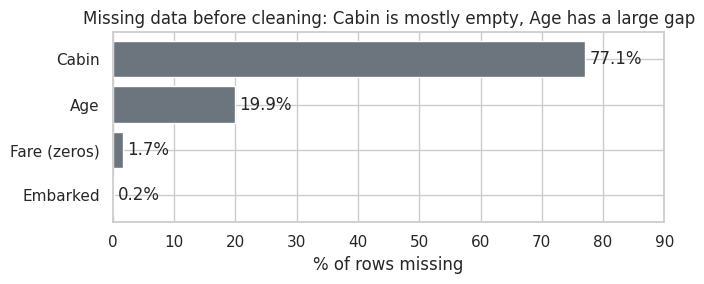

In [35]:
mq = raw_quality[raw_quality["missing"] > 0]
mq = pd.concat([mq["missing_%"], pd.Series({"Fare (zeros)": (raw["Fare"] == 0).mean() * 100})]).sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(mq.index, mq.values, color="#6c757d")
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in mq.values], padding=3)
ax.set_xlabel("% of rows missing"); ax.set_xlim(0, 90)
ax.set_title("Missing data before cleaning: Cabin is mostly empty, Age has a large gap")
plt.tight_layout(); plt.show()

### 5.2 Who survived? Comparing groups (bar charts with an average line)

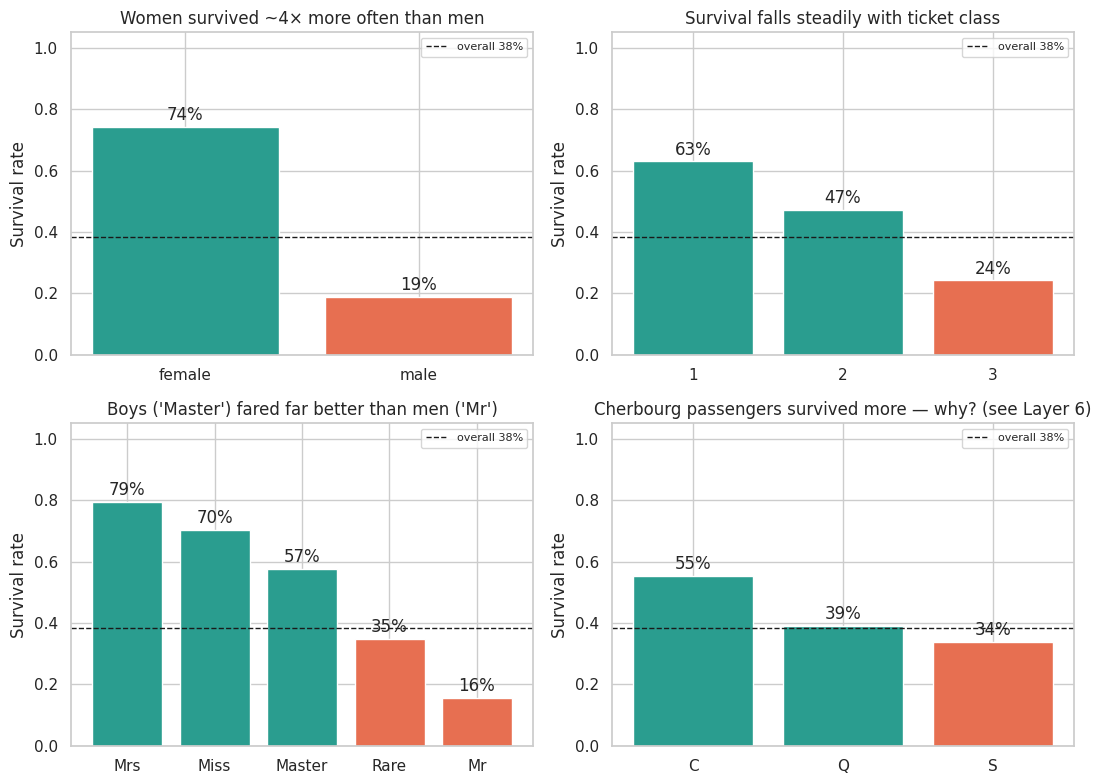

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
rate_bar(axes[0, 0], "Sex", title="Women survived ~4× more often than men")
rate_bar(axes[0, 1], "Pclass", order=[1, 2, 3], title="Survival falls steadily with ticket class")
rate_bar(axes[1, 0], "Title", title="Boys ('Master') fared far better than men ('Mr')")
rate_bar(axes[1, 1], "Embarked", order=["C", "Q", "S"], title="Cherbourg passengers survived more — why? (see Layer 6)")
plt.tight_layout(); plt.show()

### 5.3 Two factors at once: heatmap of Sex × Class

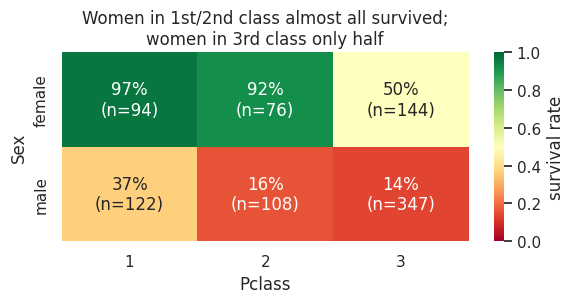

In [37]:
pivot = pd.pivot_table(full_clean, values="Survived", index="Sex", columns="Pclass", aggfunc="mean")
counts = pd.pivot_table(full_clean, values="Survived", index="Sex", columns="Pclass", aggfunc="count")
annot = pivot.map(lambda v: f"{v:.0%}") + "\n(n=" + counts.astype(str) + ")"
fig, ax = plt.subplots(figsize=(6, 3.2))
sns.heatmap(pivot, annot=annot, fmt="", cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "survival rate"}, ax=ax)
ax.set_title("Women in 1st/2nd class almost all survived;\nwomen in 3rd class only half")
plt.tight_layout(); plt.show()

### 5.4 Distributions: age and fare by outcome

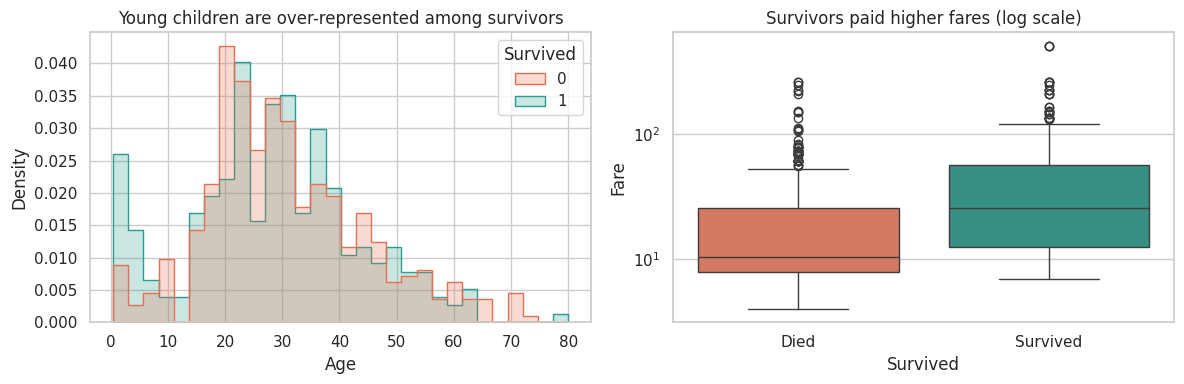

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
obs = df[df["Age"].notna()]                    # plot only real (non-imputed) ages
sns.histplot(data=obs, x="Age", hue="Survived", bins=30, element="step", stat="density",
             common_norm=False, palette={0: "#e76f51", 1: "#2a9d8f"}, ax=axes[0])
axes[0].set_title("Young children are over-represented among survivors")
sns.boxplot(data=full_clean, x="Survived", y="Fare", hue="Survived", legend=False,
            palette={0: "#e76f51", 1: "#2a9d8f"}, ax=axes[1])
axes[1].set_yscale("log"); axes[1].set_xticks([0, 1], ["Died", "Survived"])
axes[1].set_title("Survivors paid higher fares (log scale)")
plt.tight_layout(); plt.show()

### 5.5 A non-linear pattern: family size (line chart for an ordered variable)

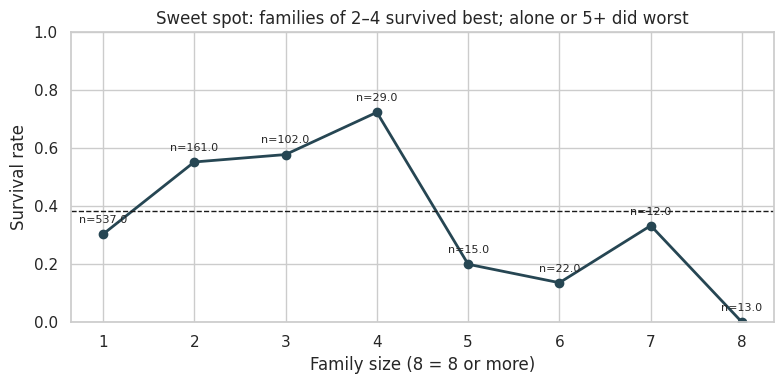

In [39]:
fam = full_clean.assign(FamilySize=full_clean["FamilySize"].clip(upper=8)).groupby("FamilySize")["Survived"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fam.index, fam["mean"], marker="o", lw=2, color="#264653")
for x, (m, n) in fam.iterrows():
    ax.annotate(f"n={n}", (x, m), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.axhline(OVERALL, ls="--", c="k", lw=1)
ax.set_xlabel("Family size (8 = 8 or more)"); ax.set_ylabel("Survival rate"); ax.set_ylim(0, 1)
ax.set_title("Sweet spot: families of 2–4 survived best; alone or 5+ did worst")
plt.tight_layout(); plt.show()

### 5.6 Feature relationships: correlation heatmap of selected features

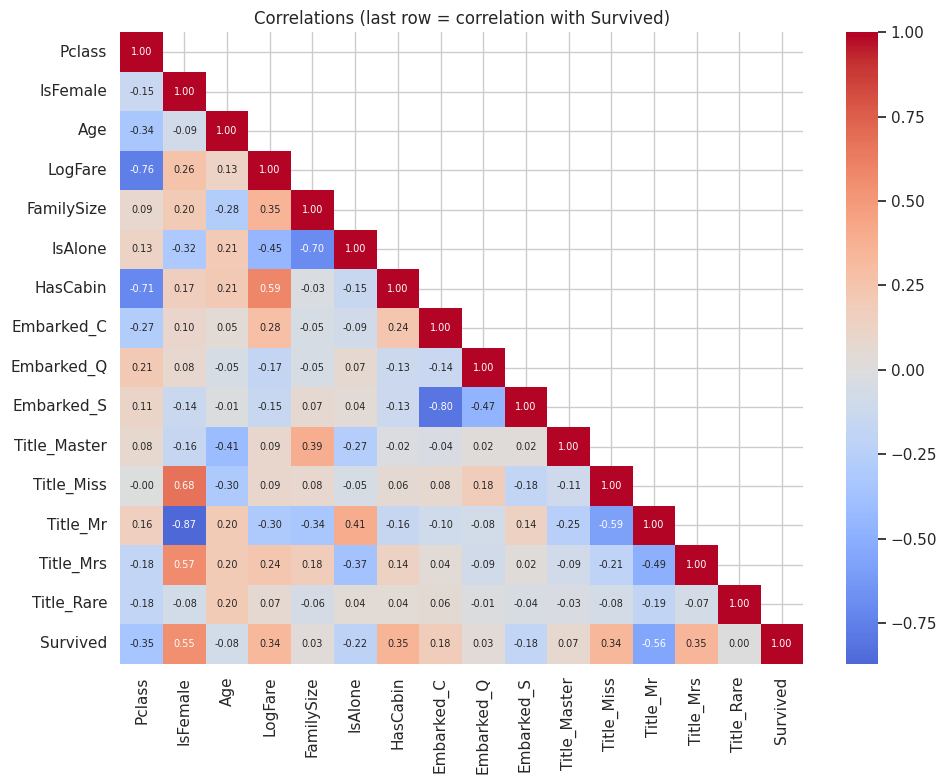

In [40]:
fig, ax = plt.subplots(figsize=(10, 8))
c = pd.concat([X_train, y_train], axis=1).corr()
sns.heatmap(c, mask=np.triu(np.ones_like(c, dtype=bool), k=1), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlations (last row = correlation with Survived)")
plt.tight_layout(); plt.show()

### 5.7 Model comparison: metrics side by side

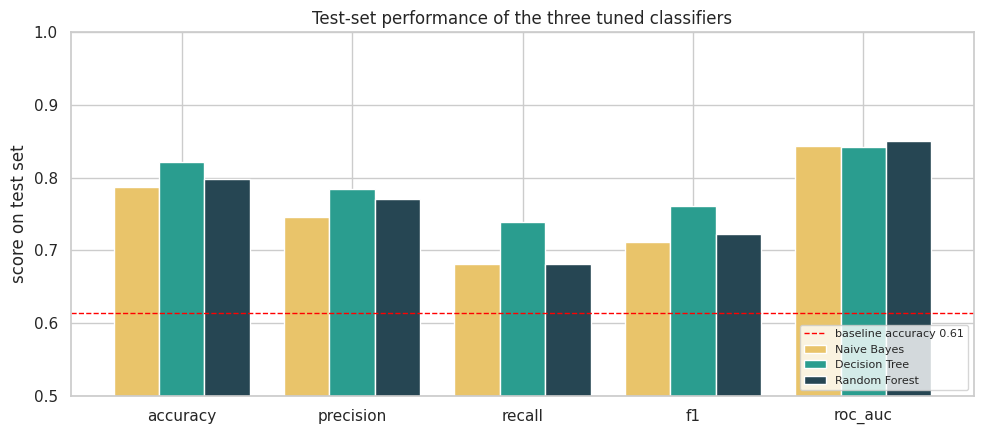

In [41]:
plot_df = test_results[["accuracy", "precision", "recall", "f1", "roc_auc"]]
ax = plot_df.T.plot(kind="bar", figsize=(10, 4.5), width=0.8, color=["#e9c46a", "#2a9d8f", "#264653"])
ax.axhline(baseline_acc, ls="--", c="red", lw=1, label=f"baseline accuracy {baseline_acc:.2f}")
ax.set_ylim(0.5, 1); ax.set_ylabel("score on test set"); ax.set_xticklabels(plot_df.columns, rotation=0)
ax.set_title("Test-set performance of the three tuned classifiers"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 5.8 ROC curves — ranking quality at every threshold
Each curve shows the trade-off between catching survivors (true-positive rate) and false alarms (false-positive rate) as the decision threshold moves. The closer the curve hugs the top-left corner, the better; the diagonal is random guessing.

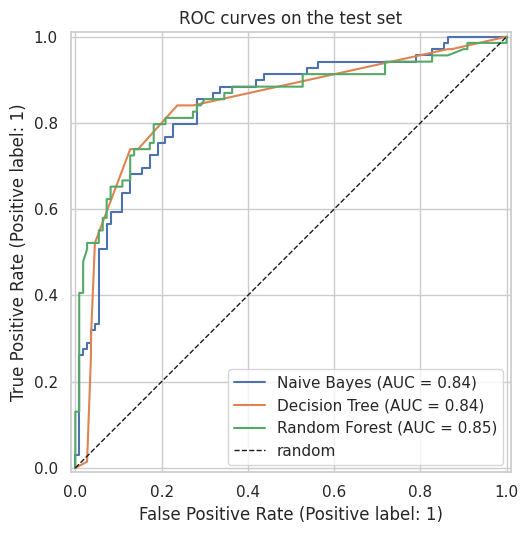

In [42]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for name in tuned:
    RocCurveDisplay.from_predictions(y_test, probas[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random")
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 5.9 Confusion matrices — *what kind* of mistakes?
Rows = truth, columns = prediction. Top-right = **false positives** (predicted survived, actually died); bottom-left = **false negatives** (missed survivors).

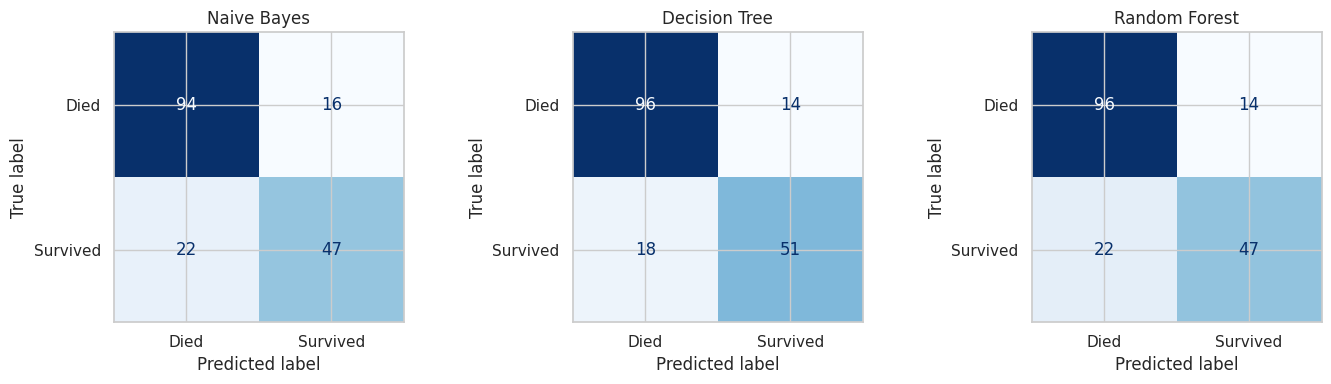

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, tuned):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], display_labels=["Died", "Survived"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 5.10 What drove the predictions? Permutation importance
**Permutation importance** works for *any* model (including Naive Bayes, which has no built-in importance): shuffle one feature's values in the test set and measure how much accuracy drops. A big drop = the model relied on that feature. Computing it on the test set shows what matters for *generalization*.

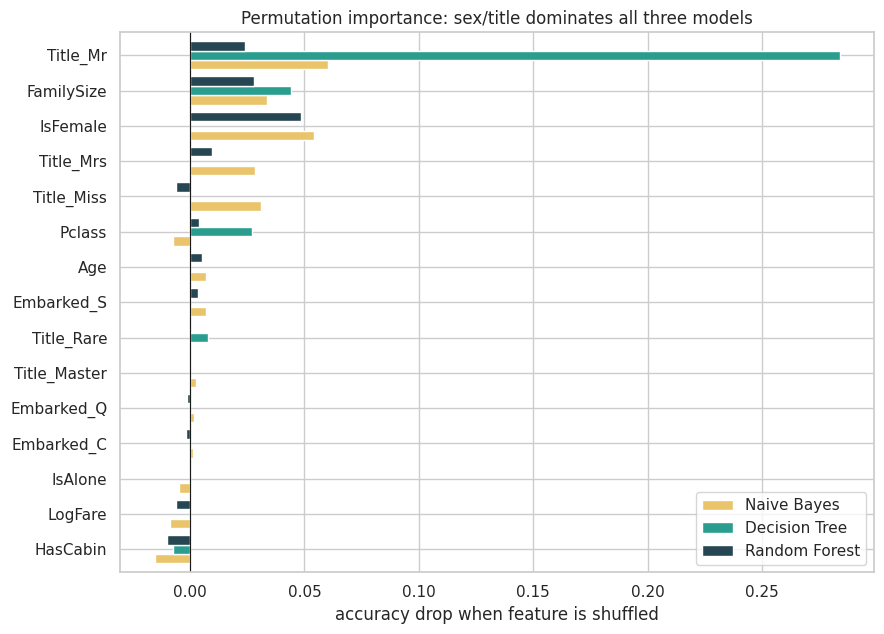

,Naive Bayes,Decision Tree,Random Forest
Title_Mr,0.060,0.284,0.024
FamilySize,0.034,0.044,0.028
IsFemale,0.054,0.000,0.049
Title_Mrs,0.028,0.000,0.010
Title_Miss,0.031,0.000,-0.006
Pclass,-0.007,0.027,0.004
Age,0.007,0.000,0.005
Embarked_S,0.007,0.000,0.004


In [44]:
imp = {}
for name, model in tuned.items():
    r = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="accuracy")
    imp[name] = pd.Series(r.importances_mean, index=FEATURES)
imp = pd.DataFrame(imp)
order = imp.mean(axis=1).sort_values().index
ax = imp.loc[order].plot(kind="barh", figsize=(9, 6.5), width=0.8, color=["#e9c46a", "#2a9d8f", "#264653"])
ax.axvline(0, c="k", lw=0.8); ax.set_xlabel("accuracy drop when feature is shuffled")
ax.set_title("Permutation importance: sex/title dominates all three models")
plt.tight_layout(); plt.show()
imp.loc[order[::-1]].round(3).head(8)

**Reading this chart:** all three models depend most on the sex/title group. Notice the Decision Tree puts all its weight on `Title_Mr` and none on `IsFemale` — not because sex doesn't matter, but because `Title_Mr` ("adult man") already contains that information and the tree picked it first. **When features are redundant, importance is split or shifted between them**, so never read a low importance as "this factor doesn't matter in reality". Small **negative** values (e.g. `HasCabin`) mean shuffling made no real difference — it's noise, not harm.

### 5.11 The decision tree itself — a model you can read
Below are the top levels of the tuned tree. Each box shows the split question, Gini impurity, number of passengers, and class counts `[died, survived]`. Colour = majority class (orange = died, blue = survived).

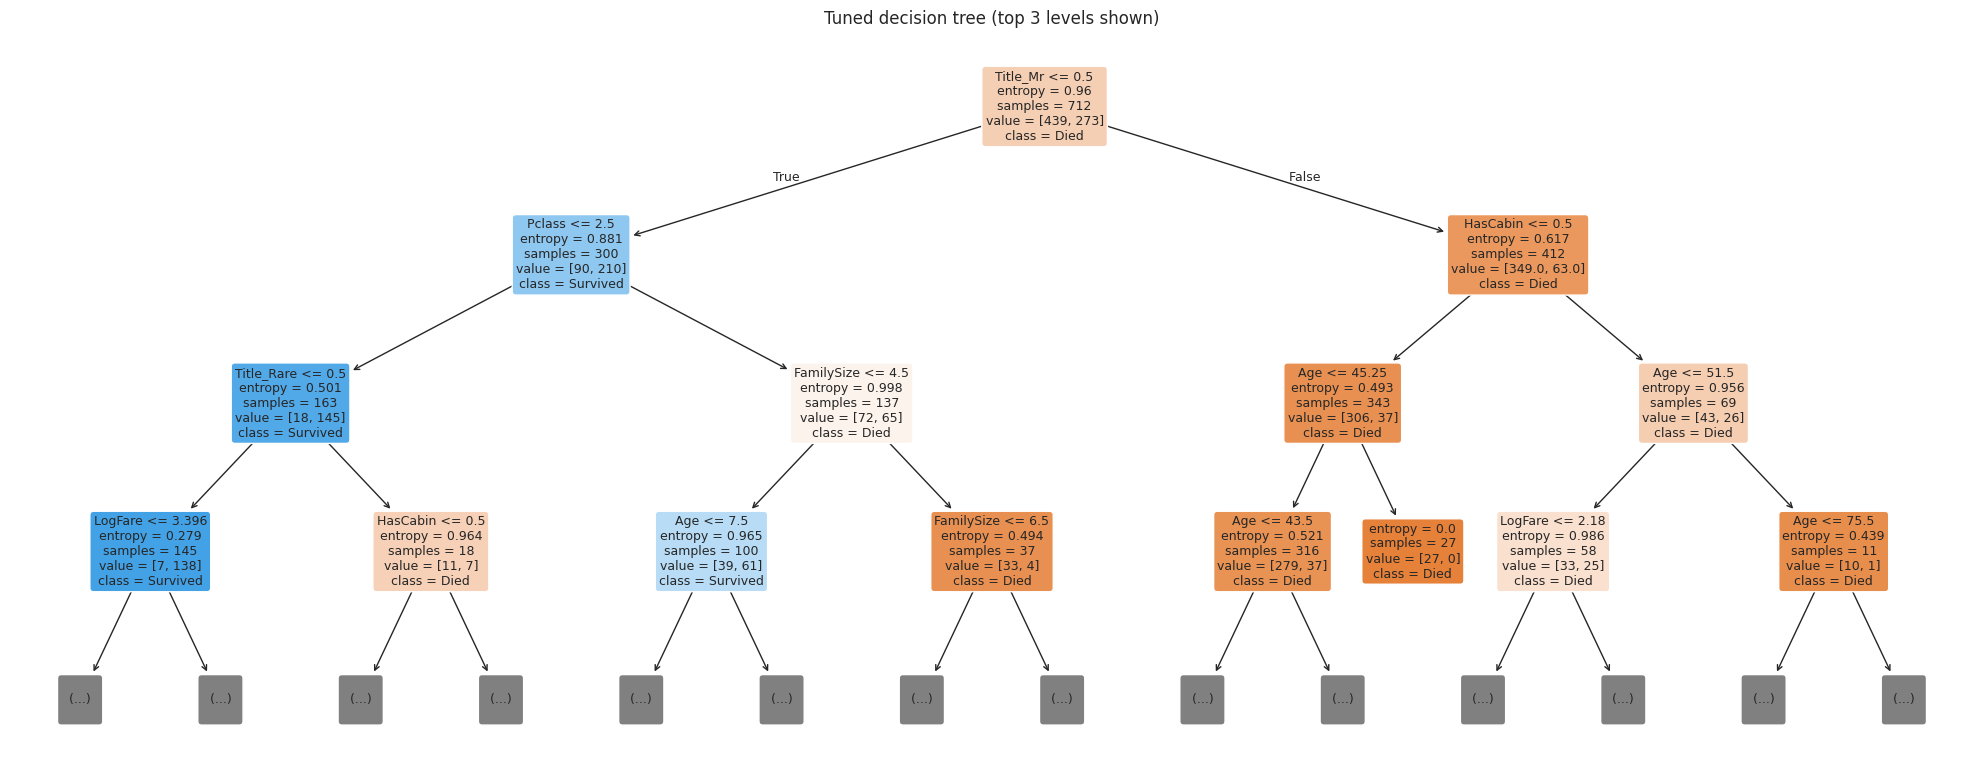

|--- Title_Mr <= 0.50
|   |--- Pclass <= 2.50
|   |   |--- Title_Rare <= 0.50
|   |   |   |--- LogFare <= 3.40
|   |   |   |   |--- class: 1
|   |   |   |--- LogFare >  3.40
|   |   |   |   |--- class: 1
|   |   |--- Title_Rare >  0.50
|   |   |   |--- HasCabin <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- HasCabin >  0.50
|   |   |   |   |--- class: 1
|   |--- Pclass >  2.50
|   |   |--- FamilySize <= 4.50
|   |   |   |--- Age <= 7.50
|   |   |   |   |--- class: 1
|   |   |   |--- Age >  7.50
|   |   |   |   |--- class: 1
|   |   |--- FamilySize >  4.50
|   |   |   |--- FamilySize <= 6.50
|   |   |   |   |--- class: 0
|   |   |   |--- FamilySize >  6.50
|   |   |   |   |--- class: 0
|--- Title_Mr >  0.50
|   |--- HasCabin <= 0.50
|   |   |--- Age <= 45.25
|   |   |   |--- Age <= 43.50
|   |   |   |   |--- class: 0
|   |   |   |--- Age >  43.50
|   |   |   |   |--- class: 0
|   |   |--- Age >  45.25
|   |   |   |--- class: 0
|   |--- HasCabin >  0.50
|   |   |--- Age <= 51.50


In [45]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tuned["Decision Tree"], feature_names=FEATURES, class_names=["Died", "Survived"],
          filled=True, rounded=True, max_depth=3, fontsize=9, impurity=True, proportion=False, ax=ax)
ax.set_title("Tuned decision tree (top 3 levels shown)")
plt.tight_layout(); plt.show()
print(export_text(tuned["Decision Tree"], feature_names=FEATURES, max_depth=3))

The text version reads as **if–then rules** — that is the main reason decision trees are loved in business settings.

> **Layer 5 takeaway:** each chart answers one question, its title states the finding, and model charts show not just *how good* but *what kind of errors* and *why*.

---
# LAYER 6 — Decision Making: How to Extract Useful Insight
This is the top of the pyramid and the part most people skip. A table is a **fact**. A chart is a **picture of a fact**. An **insight** is a fact that has been *compared, explained, checked and connected to an action*.

## 6.1 The insight ladder (use this every time)
| Rung | Question you ask | Example |
|---|---|---|
| 1. **Observation** | What does the data show? | "74% of women survived vs 19% of men." |
| 2. **Comparison** | Compared to what? How big is the gap? (use lift) | "Women: lift ≈ 1.9; men ≈ 0.5 → a ~4× difference." |
| 3. **Explanation** | *Why* might this be? | "'Women and children first' evacuation protocol." |
| 4. **Validation** | Does it survive a second look? (other data cuts, the model, confounders) | "All three models rank sex/title as the #1 driver." |
| 5. **Implication / Action** | So what? What should someone do differently? | "Evacuation policy, not just luck, decided survival — protocols must apply equally to all decks." |
| 6. **Confidence & limits** | How sure are we? What could make this wrong? | "Large groups, consistent across methods → high confidence." |

If you can't climb past rung 1, you have a statistic, not an insight. The three most powerful habits:
1. **Always compare** (to the average, to another group).
2. **Look for interactions** — a factor that changes the effect of another.
3. **Hunt for confounders** before claiming a cause.

Let's apply the ladder to six findings.

## 6.2 Insight 1 — Sex was the strongest single driver of survival

In [46]:
s = survival_report(full_clean, ["Sex"])
s

passengers  survivors  survival_rate   lift
feature value                                              
Sex     female         314        233          0.742  1.933
        male           577        109          0.189  0.492

- **Observation:** women ≈ 74% survived; men ≈ 19%.
- **Comparison:** ~4× higher survival; female lift ≈ 1.9 vs male ≈ 0.5 — the largest gap of any feature.
- **Explanation:** the "women and children first" protocol was applied to lifeboat boarding.
- **Validation:** independent methods agree — mutual information, χ², the **first split** of the decision tree (`Title_Mr` = "adult man?"), and permutation importance in all three models all point to sex/title. **Agreement across methods (triangulation) is what turns a pattern into a trusted insight.**
- **Action:** in any emergency-policy analysis, the boarding rule itself is the dominant lever — outcomes were *decided by policy*, not chance.

## 6.3 Insight 2 — Wealth bought survival (and several features measure the same thing)

In [47]:
wealth = full_clean.groupby("Pclass").agg(passengers=("Survived", "size"), survival_rate=("Survived", "mean"),
                                         median_fare=("Fare", "median"), share_with_cabin=("HasCabin", "mean"))
wealth.round(3)

,passengers,survival_rate,median_fare,share_with_cabin
Pclass,,,,
1,216,0.630,61.679,0.815
2,184,0.473,15.048,0.087
3,491,0.242,8.050,0.024


- **Observation:** 1st class ≈ 63%, 2nd ≈ 47%, 3rd ≈ 24% survival.
- **Comparison:** a clear monotonic gradient; 1st-class passengers survived ~2.6× more often than 3rd.
- **Explanation:** upper decks were closer to the lifeboats; lower-deck passengers had longer, more confusing routes and some barriers.
- **Validation:** `Pclass`, `LogFare` and `HasCabin` are all *proxies for the same underlying factor* (socio-economic status) — notice cabin records exist for most 1st-class and few 3rd-class passengers. This is why they are correlated, and why each one shows only *modest* permutation importance: shuffle one proxy and the others still carry the information.
- **Lesson for insight-hunting:** when several features tell the same story, **name the hidden factor behind them** ("wealth / proximity to lifeboats") — that is more useful than listing three separate features.

## 6.4 Insight 3 — The interaction: the protocol was not applied equally

In [48]:
inter = full_clean.groupby(["Sex", "Pclass"])["Survived"].agg(passengers="count", survival_rate="mean")
inter.round(3)

passengers  survival_rate
Sex    Pclass                           
female 1               94          0.968
       2               76          0.921
       3              144          0.500
male   1              122          0.369
       2              108          0.157
       3              347          0.135

- **Observation:** women in 1st/2nd class survived at ~92–97%; women in 3rd class at ~50%. Men in 1st class ≈ 37% vs ≈ 14–16% in 2nd/3rd.
- **Comparison:** being female helped everyone, but *how much* depended on class. That is an **interaction** — the effect of one feature changes with another.
- **Explanation:** "women first" worked where women could physically reach the boats in time.
- **Why it matters:** a single-factor summary ("women survived") hides that half of 3rd-class women died. **Interactions are where the most valuable, non-obvious insights live.** Tree-based models capture them automatically — one reason they beat Naive Bayes here.
- **Action:** a policy is only as good as its *access* — equal rules + unequal access = unequal outcomes.

## 6.5 Insight 4 — \"Children first\" was real, especially for boys

In [49]:
kids = full_clean.assign(group=np.select(
    [(full_clean["Sex"] == "male") & (full_clean["Age"] < 13),
     (full_clean["Sex"] == "male") & (full_clean["Age"] >= 13),
     (full_clean["Sex"] == "female") & (full_clean["Age"] < 13),
     (full_clean["Sex"] == "female") & (full_clean["Age"] >= 13)],
    ["boy (<13)", "man", "girl (<13)", "woman"], default="other"))
kids.groupby("group")["Survived"].agg(passengers="count", survival_rate="mean").round(3)

,passengers,survival_rate
group,,
boy (<13),41,0.561
girl (<13),32,0.594
man,536,0.160
woman,282,0.759


- **Observation:** boys survived ~3.5× more often than men (56% vs 16%). Surprisingly, girls (59%) did *worse* than adult women (76%).
- **Explanation:** age mattered mainly for males — adult women were already protected by the sex rule. The girls' result looks odd until you check class: **~72% of girls under 13 were in 3rd class** (large poor families), so class pulls their rate down. Another example of digging one level deeper before trusting a number.
- **Lesson:** this is why we **kept `Title_Master`** in feature selection despite its correlation with sex — it encodes "male *and* child", which neither `IsFemale` nor a linear use of `Age` captures alone. Domain-driven feature engineering produced a real gain.

## 6.6 Insight 5 — Family size has a sweet spot (non-linear effect)

In [50]:
fam_group = pd.cut(full_clean["FamilySize"], bins=[0, 1, 4, 20], labels=["alone (1)", "small (2-4)", "large (5+)"])
full_clean.groupby(fam_group, observed=True)["Survived"].agg(passengers="count", survival_rate="mean").round(3)

,passengers,survival_rate
FamilySize,,
alone (1),537,0.304
small (2-4),292,0.579
large (5+),62,0.161


- **Observation:** small families (2–4) ≈ 58%; alone ≈ 30%; large (5+) ≈ 16%.
- **Explanation (hypothesis):** a small family looks after each other and includes women/children (who were prioritized); people alone were mostly adult men; large families were mostly 3rd class and struggled to gather everyone in time.
- **Confidence check:** part of this effect is **explained by other variables** (solo travellers are mostly men; large families mostly 3rd class). Always ask: *"Is this its own effect, or is it another variable in disguise?"* → that's exactly the next insight.

## 6.7 Insight 6 — The confounding trap: did the port of embarkation matter?
Raw numbers say Cherbourg (C) passengers survived far more than Southampton (S). Should we conclude that boarding at Cherbourg *caused* survival? Let's check.

In [51]:
print("Raw survival rate by port:")
print(full_clean.groupby("Embarked")["Survived"].mean().round(3).to_string(), "\n")
print("Class mix by port (row %):")
print(pd.crosstab(full_clean["Embarked"], full_clean["Pclass"], normalize="index").round(3).to_string(), "\n")
print("Survival by port WITHIN each class:")
print(pd.pivot_table(full_clean, values="Survived", index="Embarked", columns="Pclass", aggfunc="mean").round(3).to_string())

Raw survival rate by port:
Embarked
C    0.554
Q    0.390
S    0.339 

Class mix by port (row %):
Pclass        1      2      3
Embarked                     
C         0.506  0.101  0.393
Q         0.026  0.039  0.935
S         0.200  0.254  0.546 

Survival by port WITHIN each class:
Pclass        1      2      3
Embarked                     
C         0.694  0.529  0.379
Q         0.500  0.667  0.375
S         0.589  0.463  0.190


- **Observation:** C ≈ 55% vs S ≈ 34%.
- **Hidden factor:** about half of Cherbourg passengers were 1st class, vs under a fifth from Southampton. **Class is a confounder** — it affects both the port someone boarded at and their survival.
- **Controlling for it:** within 1st and 2nd class the C-vs-S gap shrinks to 6–10 points (from 21 overall). Much of the "port effect" was a "class effect" in disguise.
- **But a gap remains in 3rd class** (C 38% vs S 19%). A good analyst keeps slicing — let's check the sex mix:

In [52]:
third = full_clean[full_clean["Pclass"] == 3]
third.groupby("Embarked").agg(passengers=("Survived", "size"),
                              share_female=("Sex", lambda x: (x == "female").mean()),
                              survival_rate=("Survived", "mean")).round(3)

,passengers,share_female,survival_rate
Embarked,,,
C,66,0.348,0.379
Q,72,0.458,0.375
S,353,0.249,0.190


- **Second confounder found:** only 25% of 3rd-class Southampton passengers were women, vs 35% (Cherbourg) and 46% (Queenstown). Since women survived far more, the port with more women looks "safer". **Port → survival was mostly class + sex in disguise.**
- **Validation from models:** the `Embarked_*` features have near-zero permutation importance — once the models know class and sex, port adds little.
- **Lesson:** *correlation is not causation.* Before you report "X drives Y", always slice by the obvious suspects (class, sex, age) and see whether the effect survives. This single habit separates analysts from chart-makers.

## 6.8 Insight from the model itself — error analysis
The best insight about a model is often in **where it fails**. Let's look at the mistakes of the tuned **Decision Tree** (our chosen model — see 6.9) on the test set.

In [53]:
best = "Decision Tree"
err = test_clean[["Name", "Sex", "Age", "Pclass", "Title", "FamilySize", "Survived"]].copy()
err["predicted"] = preds[best]
err["p_survive"] = probas[best].round(2)
err["error_type"] = np.select([(err.Survived == 0) & (err.predicted == 1), (err.Survived == 1) & (err.predicted == 0)],
                              ["False positive (predicted survive, died)", "False negative (predicted die, survived)"],
                              default="correct")
print(err["error_type"].value_counts().to_string(), "\n")
print("Profile of errors by sex and class:")
print(pd.crosstab([err["error_type"]], [err["Sex"], err["Pclass"]]).to_string())

error_type
correct                                     147
False negative (predicted die, survived)     18
False positive (predicted survive, died)     14 

Profile of errors by sex and class:
Sex                                      female         male        
Pclass                                        1   2   3    1   2   3
error_type                                                          
False negative (predicted die, survived)      0   0   0   10   2   6
False positive (predicted survive, died)      1   1   9    3   0   0
correct                                      14  17  19   17  14  66


In [54]:
err[err["error_type"] != "correct"].sort_values("p_survive").head(12)

,Name,Sex,Age,Pclass,Title,FamilySize,Survived,predicted,p_survive,error_type
587,"Frolicher-Stehli, Mr. Maxmillian",male,60.0,1,Mr,3,1,0,0.00,"False negative (predicted die, survived)"
570,"Harris, Mr. George",male,62.0,2,Mr,1,1,0,0.00,"False negative (predicted die, survived)"
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,Mr,1,1,0,0.11,"False negative (predicted die, survived)"
455,"Jalsevac, Mr. Ivan",male,29.0,3,Mr,1,1,0,0.11,"False negative (predicted die, survived)"
271,"Tornquist, Mr. William Henry",male,25.0,3,Mr,1,1,0,0.11,"False negative (predicted die, survived)"
146,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,3,Mr,1,1,0,0.11,"False negative (predicted die, survived)"
447,"Seward, Mr. Frederic Kimber",male,34.0,1,Mr,1,1,0,0.11,"False negative (predicted die, survived)"
17,"Williams, Mr. Charles Eugene",male,30.0,2,Mr,1,1,0,0.11,"False negative (predicted die, survived)"
444,"Johannesen-Bratthammer, Mr. Bernt",male,30.0,3,Mr,1,1,0,0.11,"False negative (predicted die, survived)"
607,"Daniel, Mr. Robert Williams",male,27.0,1,Mr,1,1,0,0.11,"False negative (predicted die, survived)"


**What the errors teach us:**
- **All 18 false negatives are men who survived.** The model gives adult men a low survival probability (most ≈ 0.11) — it is *confidently* wrong, and correctly so given the evidence: these survivors were exceptions (a lucky lifeboat place, crew duties) that no column in the data describes.
- **9 of the 14 false positives are 3rd-class women who died** — exactly the group from Insight 3 where the protocol broke down. Many of these sit in a leaf with probability ≈ 0.55, i.e. the model *knew* it was close to a coin flip.

**Insight:** the remaining errors come from information **not in the dataset** (exact location at the time of the collision, which lifeboat, personal choices). Adding more complex models would not fix this — only **new data sources** could. That is a decision-relevant conclusion: *it tells you where to invest next* (back to Layer 1 of the pyramid!).

## 6.9 Decision: which model, and what to tell stakeholders

In [55]:
summary = test_results[["accuracy", "f1", "roc_auc", "overfit_gap"]].round(3)
summary["interpretability"] = {"Naive Bayes": "Medium (probabilities per feature)",
                               "Decision Tree": "High (readable if-then rules)",
                               "Random Forest": "Low–Medium (needs importance plots)"}
summary

,accuracy,f1,roc_auc,overfit_gap,interpretability
Naive Bayes,0.788,0.712,0.844,0.023,Medium (probabilities per feature)
Decision Tree,0.821,0.761,0.842,0.020,High (readable if-then rules)
Random Forest,0.799,0.723,0.851,0.040,Low–Medium (needs importance plots)


**Recommendation: the tuned Decision Tree (depth 4).**
- **Performance:** best test accuracy (0.821) and F1 (0.761); in CV it is within 1 point of Random Forest — a statistical tie.
- **Generalization:** smallest overfit gap (0.020).
- **Interpretability:** every prediction is explained by ≤ 4 if–then rules — decisive for reports, regulators or a class presentation.
- **When to switch to Random Forest instead:** if you need to *rank* people by risk (it had the best ROC-AUC, 0.851) or if more data shows a consistent accuracy advantage.
- **Naive Bayes** is a fast, honest benchmark, but its independence assumption is broken by correlated features (sex/title), so it is consistently the weakest here.

**Executive summary — the insight in five sentences:**
1. Survival on the Titanic was **not random**: a model using only age, sex, class, fare and family information predicts outcomes with roughly 80%+ accuracy, versus 62% by guessing.
2. **Evacuation policy** was the largest factor: women and young boys were prioritized.
3. **Wealth/location** was the second: 1st-class passengers survived ~2.6× more than 3rd-class.
4. The two **interacted**: the protocol protected upper-class women almost completely but only half of 3rd-class women — access mattered as much as the rule.
5. Apparent effects such as **port of embarkation** were mostly class in disguise — a reminder to control for confounders before acting.

## 6.10 Limitations (always state them)
- **Sample:** 891 of ~2,200 people aboard (crew are absent) — conclusions apply to passengers only.
- **Imputation:** 20% of ages are estimates; results involving exact age carry extra uncertainty.
- **Small test set:** 179 passengers → ±3 percentage points of noise in test metrics.
- **Correlation ≠ causation:** the data is observational; explanations are hypotheses supported by history, not experiments.

> **Layer 6 takeaway:** climb the insight ladder — observe, compare, explain, validate, act, state confidence. Look for interactions and confounders. Use model errors to decide what data to collect next.

---
# Summary — The Whole Pyramid on One Page
| Layer | What we did | Key tool / concept |
|---|---|---|
| **Data Sources** | Loaded 891×12 file; wrote data dictionary; defined target & checked balance | `read_csv`, `info()`, class balance |
| **Preprocessing & Feature Selection** | Audited nulls, hidden zeros, duplicates, outliers, messy text; engineered Title/HasCabin/FamilySize; split *before* imputing; group-median imputation; log transform; one-hot encoding; MI, χ², correlation-based selection | `str.extract`, train-only `fit`, `get_dummies`, `mutual_info_classif`, `chi2` |
| **Data Exploration** | Summary stats; 5 targeted queries; standardized lift report | `describe`, `query`, `groupby`, `pivot_table`, `crosstab`, lift |
| **Data Mining** | Baseline + Naive Bayes, Decision Tree, Random Forest; 5-fold CV; grid search; final test | `cross_validate`, `GridSearchCV`, accuracy/precision/recall/F1/AUC |
| **Data Presentation** | 11 charts, each with a one-sentence finding as its title | bar/heatmap/hist/box/line, ROC, confusion matrix, permutation importance, tree plot |
| **Decision Making** | 6 insights via the insight ladder, error analysis, model recommendation, limitations | compare → explain → validate → act |

---
# Self-Test Questions
<details><summary><b>1. Why do we split train/test before imputing missing ages?</b></summary>
To avoid data leakage: medians computed on all rows would include test-set information, making the test score optimistically biased.
</details>

<details><summary><b>2. Why impute Age by Title rather than by the overall mean?</b></summary>
Title encodes age group (Master = boys, Mr = adult men). A global mean would turn missing-age boys into adults and erase the "children first" signal.
</details>

<details><summary><b>3. Why did we keep the high fares instead of removing them as outliers?</b></summary>
They are real values (luxury tickets), not errors. We delete impossible values but transform extreme real ones (log1p).
</details>

<details><summary><b>4. A model gets 62% accuracy. Is that good here?</b></summary>
No — always predicting "died" already gives ~62%. Compare to the baseline and look at precision/recall/F1.
</details>

<details><summary><b>5. Why did the default Decision Tree overfit and how did we fix it?</b></summary>
Unrestricted, it grows until each leaf holds one passenger, memorising the training data (~98% train accuracy vs much lower CV). Limiting `max_depth` and `min_samples_leaf` via grid search fixed it.
</details>

<details><summary><b>6. Why is Naive Bayes weakest on this data?</b></summary>
It assumes features are independent given the class, but IsFemale, Title_Mr, Title_Mrs and Title_Miss are strongly dependent — the same evidence is counted several times.
</details>

<details><summary><b>7. What is the difference between precision and recall?</b></summary>
Precision: of predicted survivors, how many really survived. Recall: of real survivors, how many the model found.
</details>

<details><summary><b>8. Cherbourg passengers survived more. Why shouldn't we say the port caused it?</b></summary>
Class is a confounder: Cherbourg had many more 1st-class passengers. Within the same class the port gap largely disappears.
</details>

<details><summary><b>9. What is the difference between a fact and an insight?</b></summary>
A fact is an observation. An insight is a fact that has been compared, explained, validated and linked to an action, with its confidence stated.
</details>

<details><summary><b>10. What does error analysis tell us to do next?</b></summary>
The remaining errors come from information not in the data (location, lifeboat assignment), so improvement needs new data sources rather than more complex models.
</details>